# Single Asset Analyzer
**Χρήση:** γράψε ticker στο κελί «Παράμετροι» και τρέξε όλα τα κελιά (Run All).

1. **Σύνοψη:** όλοι οι δείκτες αποτίμησης σε έναν πίνακα, απέναντι στο δικό της ιστορικό.
2. **Ποιότητα:** Piotroski F-Score.
3. **Αποτίμηση αναλυτικά:** P/E, FCF yield, EV/EBIT, P/S, shareholder yield, με διαγράμματα.
4. **Αν κάτι φαίνεται περίεργο:** κελιά debug στο τέλος.

Δοκιμές, επισκευές και έλεγχοι της βάσης ζουν στο `dev/`, όχι εδώ.

In [1]:
# ── SETUP ────────────────────────────────────────────────────────────────
# DEV_MODE = True μόνο όταν μόλις άλλαξες κώδικα στο valuation/ ή στο quality_scores/
# (ξαναφορτώνει τα modules χωρίς restart). Για κανονική χρήση: False.
DEV_MODE = False

import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt

if DEV_MODE:
    import importlib
    import db, fundamentals
    from quality_scores import line_items, piotroski, piotroski_plots
    from valuation import ttm, pe, pe_plots, yields, yields_plots, ev, ev_plots, payouts, payouts_plots, snapshot
    # σειρά: πρώτα όσα δεν εξαρτώνται από άλλα (ttm), μετά όσα τα χρησιμοποιούν
    for m in (db, fundamentals, line_items, piotroski, piotroski_plots,
              ttm, pe, pe_plots, yields, yields_plots, ev, ev_plots, payouts, payouts_plots, snapshot):
        importlib.reload(m)

from db import get_engine
from quality_scores.piotroski import piotroski_f_score, print_report, piotroski_history
from quality_scores.piotroski_plots import plot_report, plot_history
from valuation.pe import (pe_history, print_pe_summary, print_peer_coverage,
                          print_band_summary, print_decomposition, debug_ttm)
from valuation.pe_plots import plot_pe, plot_pe_bands, plot_decomposition
from valuation.yields import fcf_history, print_fcf_summary, debug_fcf
from valuation.yields_plots import plot_fcf
from valuation.ev import ev_history, print_ev_summary, debug_ev
from valuation.ev_plots import plot_ev
from valuation.payouts import payout_history, print_payout_summary
from valuation.payouts_plots import plot_payouts
from valuation.snapshot import print_snapshot

eng = get_engine()
print(f"✅ Έτοιμο | DEV_MODE={'ON' if DEV_MODE else 'OFF'}")

✅ Έτοιμο | DEV_MODE=OFF


In [2]:
# ── ΠΑΡΑΜΕΤΡΟΙ ───────────────────────────────────────────────────────────
TICKER = "MSFT"
AS_OF = None            # π.χ. "2022-06-30": ό,τι ήξερε η αγορά εκείνη τη μέρα
YEARS = 10              # πόσα χρόνια ιστορικού για τις συγκρίσεις
PEER_GROUP = "sector"   # ή "industry" (στενότερη ομάδα, λιγότερες εταιρείες)

# ΣΥΝΟΨΗ — ΑΠΟΤΙΜΗΣΗ ΜΕ ΜΙΑ ΜΑΤΙΑ
Κάθε δείκτης συγκρίνεται με **το δικό της** ιστορικό των τελευταίων `YEARS` ετών.

«Φθηνότερη από 80% των ημερών» = στο 80% των προηγούμενων ημερών ήταν ακριβότερη απ' ό,τι σήμερα.

    ≥ 75%  → φθηνή για τα δικά της δεδομένα
    ≤ 25%  → ακριβή για τα δικά της δεδομένα
    αλλιώς → κοντά στα συνηθισμένα της

Αν οι δείκτες **διαφωνούν** (π.χ. φθηνό P/E αλλά ακριβό FCF yield), η αιτία είναι συνήθως ενδιαφέρουσα:
μεγάλες επενδύσεις (capex), χρέος ή εφάπαξ κέρδη. Δες τις αναλυτικές ενότητες παρακάτω.
Αυτό το κελί κατεβάζει όλα τα δεδομένα μία φορά· τα επόμενα κελιά τα ξαναχρησιμοποιούν.

In [3]:
# ── ΣΥΝΟΨΗ ───────────────────────────────────────────────────────────────
pe  = pe_history(TICKER, eng, years=YEARS, as_of=AS_OF, peer_group=PEER_GROUP)
fcf = fcf_history(TICKER, eng, years=YEARS, as_of=AS_OF)
ev  = ev_history(TICKER, eng, as_of=AS_OF, base=fcf)       # ίδιες τιμές/μετοχές με το fcf
po  = payout_history(TICKER, eng, as_of=AS_OF, base=fcf)

print()
print_snapshot(TICKER, pe=pe, fcf=fcf, ev=ev, po=po);

⬇️  Τιμές + EPS για MSFT και 103 peers (Technology)...

══ MSFT — αποτίμηση με μια ματιά (ιστορικό από 10/2016) ══
          Δείκτης Σήμερα Διάμεσος της ίδιας Φθηνότερη από % ημερών                        Ανάγνωση
        P/E (TTM)   29.5               33.1                    69%       κοντά στα συνηθισμένα της
    EV/EBIT (TTM)   25.2               27.5                    69%       κοντά στα συνηθισμένα της
        FCF yield  1.70%              2.86%                     0% ακριβή για τα δικά της δεδομένα
        P/S (TTM)  11.88              10.56                    31%       κοντά στα συνηθισμένα της
Shareholder yield  1.24%              2.34%                                           πληροφοριακό

Σύγκριση μόνο με το δικό της παρελθόν, όχι με τον κλάδο. Περιγραφή, όχι σήμα αγοράς/πώλησης.


# PIOTROSKI F-SCORE
## ΤΙ ΕΙΝΑΙ:
9 ερωτήσεις "ναι/όχι" για την οικονομική υγεία μιας εταιρείας,
συγκρίνοντας την τελευταία χρονιά (φέτος) με την προηγούμενη (πέρσι).
Κάθε "ναι" = 1 πόντος. Γενικά: 7–9 = υγιής, 0–3 = αδύναμη.
Αν λείπει κάποιο νούμερο, η ερώτηση ΔΕΝ μετράει ως αποτυχία — γράφεται
"δεν αξιολογήθηκε" και το score δίνεται ως "πόντοι / όσα ελέγχθηκαν".

## - ΚΕΡΔΟΦΟΡΙΑ -

## 1. Κερδοφόρα (ROA > 0)
    Έβγαλε κέρδος φέτος;  ROA = κέρδη / assets στην ΑΡΧΗ της χρονιάς.
    Παράδειγμα: κέρδη 10, assets αρχής 100 → ROA 10% → ΝΑΙ.

## 2. Θετικές ταμειακές ροές (CFO > 0)
    Μπήκαν πραγματικά χρήματα στο ταμείο από τη λειτουργία της εταιρείας;
    τα κέρδη μπορεί να είναι "στα χαρτιά" — το ταμείο δεν ξεγελιέται εύκολα.

## 3. ROA βελτιώθηκε
    Η κερδοφορία ανά ευρώ assets ανέβηκε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 9%, φέτος 11% → ΝΑΙ.
    Γιατί assets ΑΡΧΗΣ χρονιάς: αν η εταιρεία αγόρασε άλλη τον Δεκέμβριο
    και τα assets διπλασιάστηκαν, αυτά δεν δούλεψαν όλη τη χρονιά. Με τα
    assets του τέλους θα φαινόταν ψευδώς ότι η κερδοφορία έπεσε στο μισό.

## 4. Ταμείο > λογιστικά κέρδη
    Οι ταμειακές ροές είναι μεγαλύτερες από τα κέρδη;
    Παράδειγμα: κέρδη 10, ταμείο 14 → ΝΑΙ (τα κέρδη "στηρίζονται" σε
    μετρητά). Αν ήταν κέρδη 10, ταμείο 3 → ΟΧΙ: μεγάλο μέρος των κερδών
    είναι απαιτήσεις/λογιστικές εγγραφές, κλασικό προειδοποιητικό σημάδι.

## - ΧΡΕΟΣ & ΡΕΥΣΤΟΤΗΤΑ - 

## 5. Λιγότερο χρέος
    Μακροπρόθεσμο χρέος / ΜΕΣΟ ΟΡΟ assets έπεσε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 25%, φέτος 20% → ΝΑΙ.
    Συγκρίνεται πάντα το ΙΔΙΟ μέτρο και τις δύο χρονιές: αν πέρσι
    δηλώθηκαν δύο κομμάτια χρέους (30 + 70) και φέτος μόνο το ένα (70),
    συγκρίνουμε 70 με 70 — όχι 100 με 70, που θα έδειχνε ψεύτικη μείωση.

## 6. Καλύτερη ρευστότητα (current ratio)
    Current ratio = ό,τι γίνεται μετρητά μέσα σε 1 χρόνο / ό,τι πρέπει
    να πληρωθεί μέσα σε 1 χρόνο. Ανέβηκε σε σχέση με πέρσι;
    Παράδειγμα: πέρσι 1.40x, φέτος 1.25x → ΟΧΙ.

## 7. Όχι νέες μετοχές
    Ο αριθμός μετοχών έμεινε ίδιος ή μειώθηκε; Νέες μετοχές = η πίτα
    μοιράζεται σε περισσότερους (dilution). Buybacks = ΝΑΙ.
    Αν ο αριθμός άλλαξε κατά ~x2, x4, x10 κτλ. είναι πιθανότατα split
    (π.χ. AAPL 4:1 το 2020: 4.4B → 17B μετοχές) → "δεν αξιολογήθηκε",
    γιατί το split δεν είναι dilution.

## - ΑΠΟΔΟΤΙΚΟΤΗΤΑ - 

## 8. Μεικτό περιθώριο ↑
    Από κάθε 100€ πωλήσεων, πόσα μένουν μετά το κόστος του προϊόντος;
    Παράδειγμα: πέρσι 37.8€, φέτος 38.2€ → ΝΑΙ (καλύτερη τιμολόγηση ή
    φθηνότερη παραγωγή).

## 9. Αποδοτικότητα assets ↑ (asset turnover)
    Πόσες πωλήσεις βγάζει κάθε 1€ assets (αρχής χρονιάς);
    Παράδειγμα: πέρσι 0.71€, φέτος 0.81€ → ΝΑΙ (τα ίδια assets "δουλεύουν" περισσότερο).

── Piotroski F-Score: MSFT ──────────────────
   FY2026 vs FY2025  (filed 2026-07-29)
   Score: 6 / 9

   Κερδοφορία
   [PASS]  Κερδοφόρα (ROA > 0)          φέτος 21.6%
   [PASS]  Θετικές ταμειακές ροές       φέτος $182.94B
   [PASS]  ROA βελτιώθηκε               πέρσι 19.9%  φέτος 21.6%
   [PASS]  Ταμείο > λογιστικά κέρδη     κέρδη $133.75B  ταμείο $182.94B

   Χρέος & ρευστότητα
   [PASS]  Λιγότερο χρέος               πέρσι 7.6%  φέτος 5.9%
            ↳ χρέος: μακροπρόθεσμο + τρέχον μέρος
   [FAIL]  Καλύτερη ρευστότητα          πέρσι 1.35x  φέτος 1.23x
   [PASS]  Όχι νέες μετοχές             πέρσι 7.43B  φέτος 7.43B
            ↳ μετοχές στο τέλος της χρονιάς

   Αποδοτικότητα
   [FAIL]  Μεικτό περιθώριο ↑           πέρσι 68.8%  φέτος 67.9%
            ↳ δηλωμένο μεικτό κέρδος
   [FAIL]  Αποδοτικότητα assets ↑       πέρσι 0.55x  φέτος 0.54x


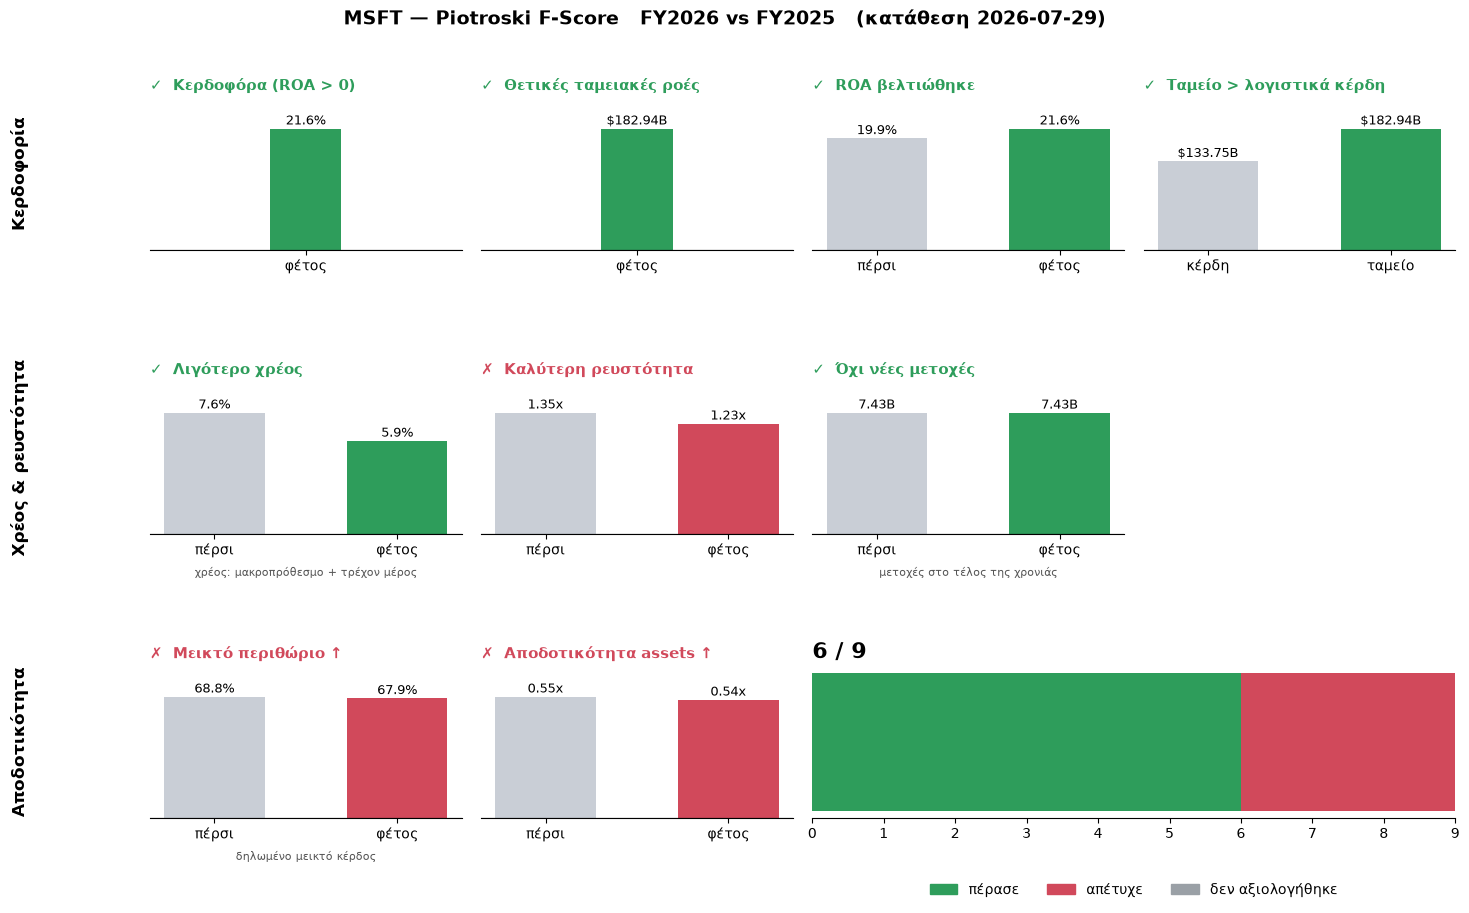

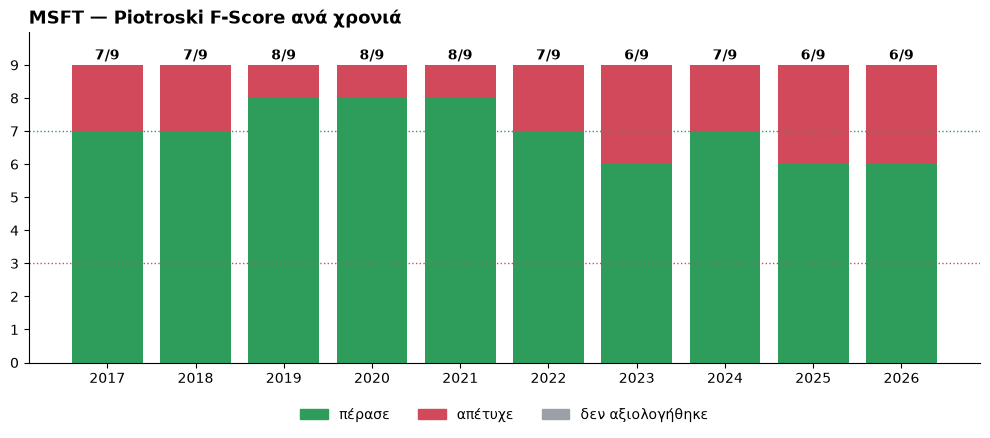

In [4]:
# ── PIOTROSKI F-SCORE ────────────────────────────────────────────────────
res = piotroski_f_score(TICKER, eng, as_of=AS_OF)
print_report(res)
plot_report(res)
plt.show()

plot_history(piotroski_history(TICKER, eng, n_years=YEARS), TICKER)
plt.show()

# P/E — ΦΘΗΝΗ Η ΑΚΡΙΒΗ;
## ΤΙ ΕΙΝΑΙ:
P/E = τιμή μετοχής / κέρδη ανά μετοχή των τελευταίων 12 μηνών (EPS TTM).
Δείχνει πόσα πληρώνεις για κάθε 1 ετήσιου κέρδους.
Παράδειγμα: τιμή 100, EPS TTM 5 → P/E 20 → "πληρώνεις 20 χρόνια κερδών".

## Πώς διαβάζεται το διάγραμμα
    Πάνω: η τιμή. Κάτω: το P/E της μετοχής (μπλε) μαζί με:
    - τη διακεκομμένη μπλε = ο "συνήθης" P/E της ίδιας στην περίοδο
      (μπλε γραμμή πάνω της → πιο ακριβή από ό,τι συνήθως),
    - την πορτοκαλί = διάμεσος P/E του κλάδου,
    - την πορτοκαλί ζώνη = εκεί βρίσκεται η "μεσαία" μισή του κλάδου.
    Γκρι φόντο = η εταιρεία είχε ζημιές → το P/E δεν ορίζεται.

## Προσοχή στην ερμηνεία
    Χαμηλό P/E ≠ αυτόματα ευκαιρία: μπορεί η αγορά να περιμένει πτώση κερδών.
    Υψηλό P/E ≠ αυτόματα φούσκα: μπορεί να περιμένει γρήγορη ανάπτυξη.
    Το P/E λέει "πόσο ακριβά πληρώνεις", όχι "αν αξίζει".

── Κάλυψη peers: sector «Technology» (103 εταιρείες) ──
   87  ok                                         AAPL, ACN, ADBE, ADI, ADP, ADSK, +81
    8  ζημιές (EPS ≤ 0)                           CRWD, INTC, LITE, S, SEDG, TRMB, +2
    7  παλιό EPS (> 270 μέρες)                    CRM, GDDY, PARA, Q, RAL, USBC, +1
    1  σταμάτησε να διαπραγματεύεται              QRVO
── MSFT — P/E (TTM) ── 2026-10-16 ──
  Τιμή 529.05 / EPS TTM 17.95 = P/E 29.5
  Διάμεσος P/E της ίδιας (2016–): 33.1  → το σημερινό είναι υψηλότερο από το 31% των ημερών
  Διάμεσος P/E sector «Technology» (87 εταιρείες): 31.7  → φθηνότερη κατά 7%


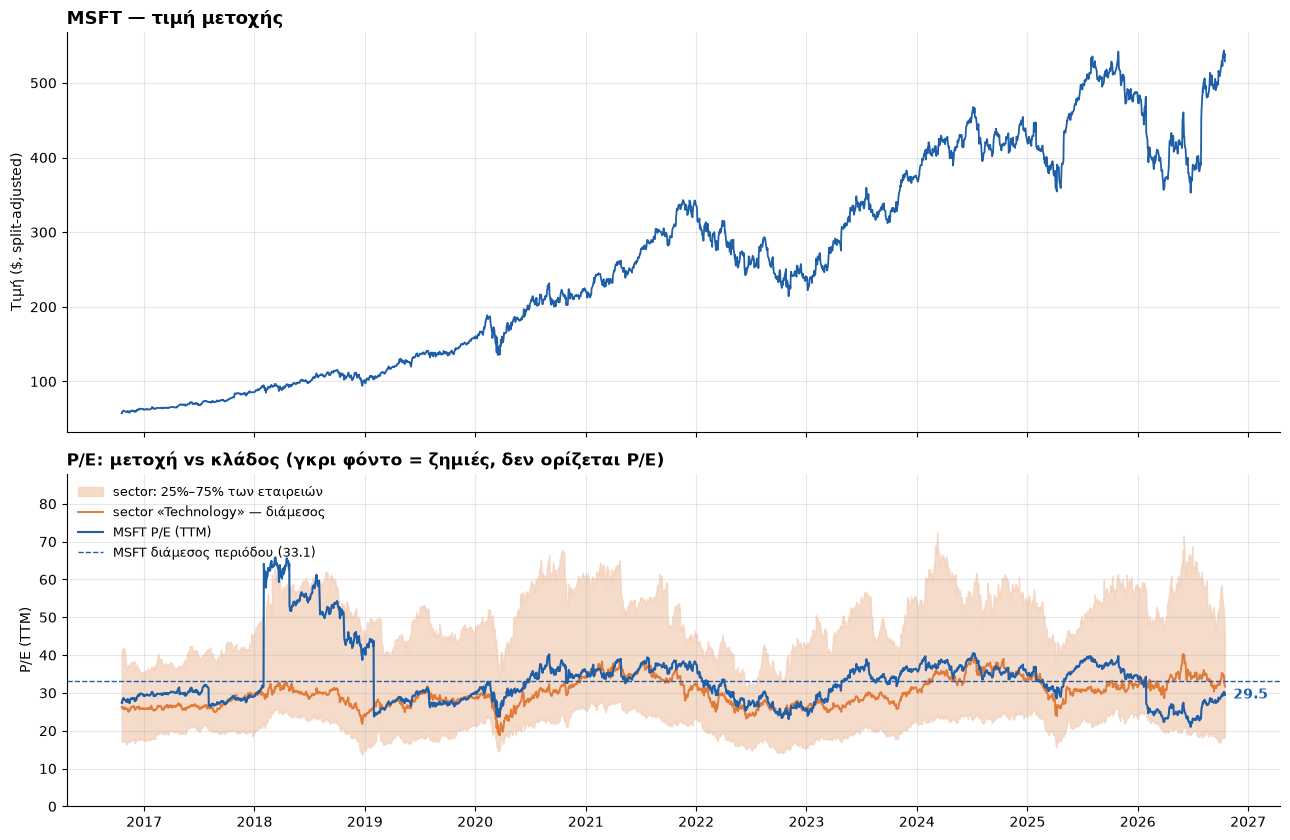

In [5]:
# ── P/E: ΤΙΜΗ & ΑΠΟΤΙΜΗΣΗ ─────────────────────────────────────────────────
print_peer_coverage(pe)
print_pe_summary(pe)
plot_pe(pe)
plt.show()

# P/E BANDS — ΠΟΥ ΘΑ ΗΤΑΝ Η ΤΙΜΗ ΣΤΟ "ΣΥΝΗΘΙΣΜΕΝΟ" P/E;
## ΤΙ ΕΙΝΑΙ:
Τιμή στο P/E X = EPS TTM × X. Αν EPS = 5 και ο συνήθης P/E της μετοχής είναι 20, η "λογική" τιμή είναι 100.
Η πράσινη ζώνη = P/E ανάμεσα στο 25% και 75% των ημερών της ίδιας της μετοχής.

    Μπλε (τιμή) κάτω από τη ζώνη → φθηνή σε σχέση με το δικό της παρελθόν
    Μπλε μέσα στη ζώνη           → κανονική αποτίμηση
    Μπλε πάνω από τη ζώνη        → ακριβή σε σχέση με το δικό της παρελθόν

Προσοχή: τα όρια υπολογίζονται από ΟΛΟ το διάστημα (και το μέλλον κάθε ημέρας) — περιγραφικό διάγραμμα, όχι σήμα για backtest.

── MSFT — P/E bands (ιστορικό της ίδιας) ──
  10% των ημερών είχε P/E κάτω από  26.4 → τιμή σήμερα θα ήταν   474.62$
  25% των ημερών είχε P/E κάτω από  28.5 → τιμή σήμερα θα ήταν   511.43$
  50% των ημερών είχε P/E κάτω από  33.1 → τιμή σήμερα θα ήταν   594.21$
  75% των ημερών είχε P/E κάτω από  36.7 → τιμή σήμερα θα ήταν   658.49$
  90% των ημερών είχε P/E κάτω από  40.2 → τιμή σήμερα θα ήταν   721.65$
  Πραγματική τιμή: 529.05$ (P/E 29.5)


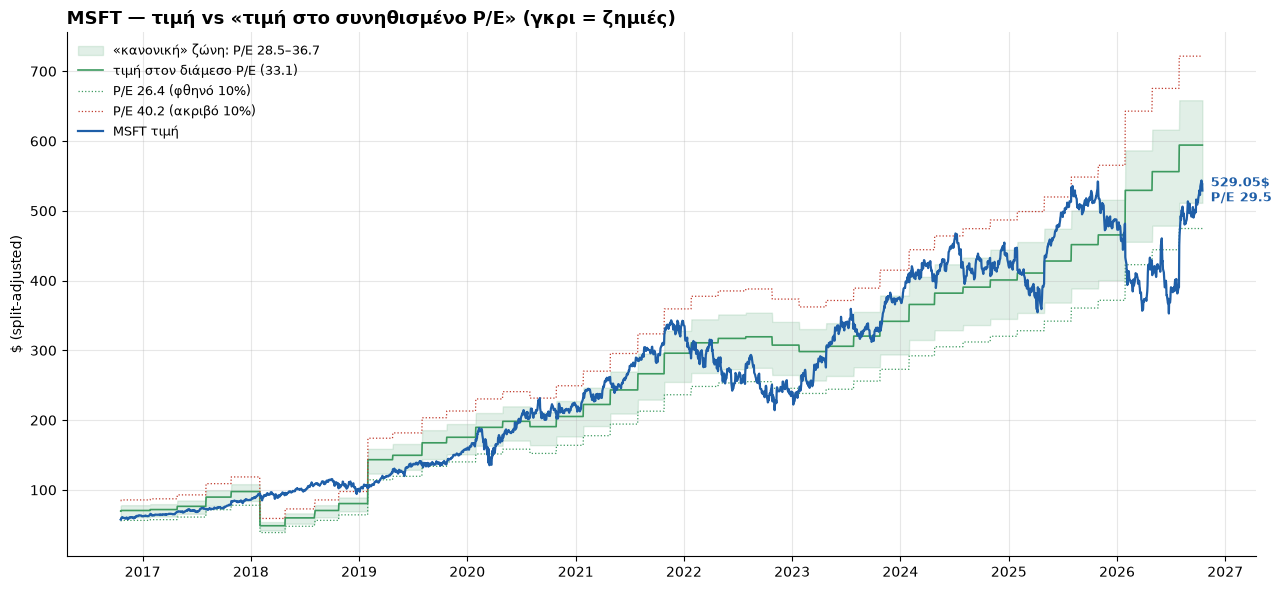

In [6]:
# ── P/E BANDS ─────────────────────────────────────────────────────────────
print_band_summary(pe)
plot_pe_bands(pe)
plt.show()

# ΑΠΟ ΠΟΥ ΗΡΘΕ Η ΑΠΟΔΟΣΗ — ΚΕΡΔΗ Η P/E;
## ΤΙ ΕΙΝΑΙ:
Τιμή = EPS × P/E, άρα μεταβολή τιμής = μεταβολή κερδών × μεταβολή P/E.
Παράδειγμα: τιμή 50$→100$ (×2) = κέρδη 2.5→4 (×1.6) × P/E 20→25 (×1.25).

    Άνοδος από κέρδη → η εταιρεία έγινε πραγματικά καλύτερη (πιο "υγιής" άνοδος)
    Άνοδος από P/E   → η αγορά απλώς πληρώνει ακριβότερα· μπορεί να γυρίσει πίσω

Χωρίς μερίσματα. Έτη με EPS κοντά στο 0 εμφανίζονται με "—" (ο διαχωρισμός δεν έχει νόημα).

── MSFT — από πού ήρθε η απόδοση (10/2016 → 10/2026, χωρίς μερίσματα) ──
  Τιμή ×9.20 = κέρδη ×8.55  ×  P/E ×1.08   (P/E 27.4 → 29.5)
  +820% συνολικά = +793% από κέρδη +27% από αλλαγή P/E
            Έτος  Τιμή %  από κέρδη %  από P/E %
2016 (από 19/10)     8.0          1.5        6.5
            2017    37.7         38.4       -0.7
            2018    18.7        -21.2       39.9
            2019    55.3         98.0      -42.7
            2020    41.0         18.7       22.3
            2021    51.2         45.3        5.9
            2022   -28.7          3.3      -32.0
            2023    56.8         13.3       43.5
            2024    12.1         16.9       -4.9
            2025    14.7         16.0       -1.3
        2026 YTD     9.4         25.6      -16.2


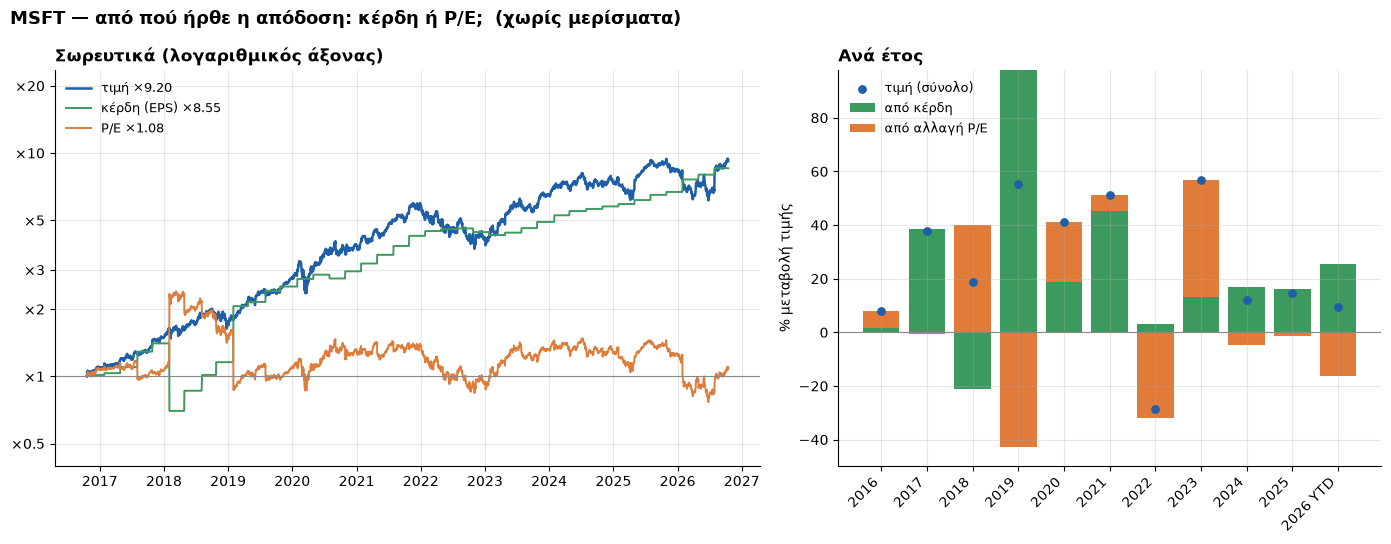

In [7]:
# ── ΑΝΑΛΥΣΗ ΑΠΟΔΟΣΗΣ ──────────────────────────────────────────────────────
print_decomposition(pe)
plot_decomposition(pe)
plt.show()

# FCF YIELD — ΠΟΣΑ ΜΕΤΡΗΤΑ ΒΓΑΖΕΙ ΣΕ ΣΧΕΣΗ ΜΕ ΤΗΝ ΤΙΜΗ ΤΗΣ;
## ΤΙ ΕΙΝΑΙ:
Free cash flow (FCF) = ταμειακές ροές από τη λειτουργία (CFO) − επενδύσεις σε πάγια (capex).
Είναι τα μετρητά που μένουν πραγματικά, και μπορούν να γίνουν μερίσματα, buybacks ή αποπληρωμή χρέους.

FCF yield = FCF των τελευταίων 12 μηνών / market cap. Είναι το αντίστροφο του P/FCF.
Παράδειγμα: FCF 71 δισ., market cap 3.000 δισ. → 2.4% (P/FCF 42).
**Ψηλό yield = φθηνή.** Αντίθετα με το P/E, ένα αρνητικό yield έχει νόημα: η εταιρεία καίει μετρητά.

## Πώς διαβάζεται το διάγραμμα
    Πάνω: CFO (μπλε), capex (πορτοκαλί), FCF (πράσινο).
          FCF πέφτει ενώ το CFO ανεβαίνει → αιτία οι επενδύσεις, όχι πιο αδύναμη επιχείρηση.
    Κάτω: FCF yield απέναντι στο δικό της ιστορικό (ζώνη 25%–75%).
          Πάνω από τη ζώνη → φθηνή για τα δικά της δεδομένα.

## Προσοχή
    Το capex είναι μόνο το ταμειακό. Εταιρείες που νοικιάζουν πολλά (leases) έχουν «πραγματικό» FCF χαμηλότερο.
    Αν λείπει το tag του capex, το FCF yield είναι «—» (≈ 160 εταιρείες, θα διορθωθεί στο ingest).

── MSFT — FCF yield (TTM) ── 2026-10-16 ──
  Market cap: 529.05$ × 7,453M μετοχές = 3,943.0 bn$
  FCF TTM: CFO 182.94 bn − capex 115.95 bn = 66.99 bn$
  FCF yield: 1.70%   (P/FCF 58.9)
  Διάμεσος της ίδιας (2016–): 2.86%  → σήμερα είναι φθηνότερη απ' ό,τι στο 0% των ημερών
  ⚠️  Κοντά στο ακριβότερο σημείο του διαστήματος. Δες το διάγραμμα: αν το CFO ανεβαίνει και πέφτει το FCF, αιτία είναι οι επενδύσεις (capex), όχι μόνο η τιμή.


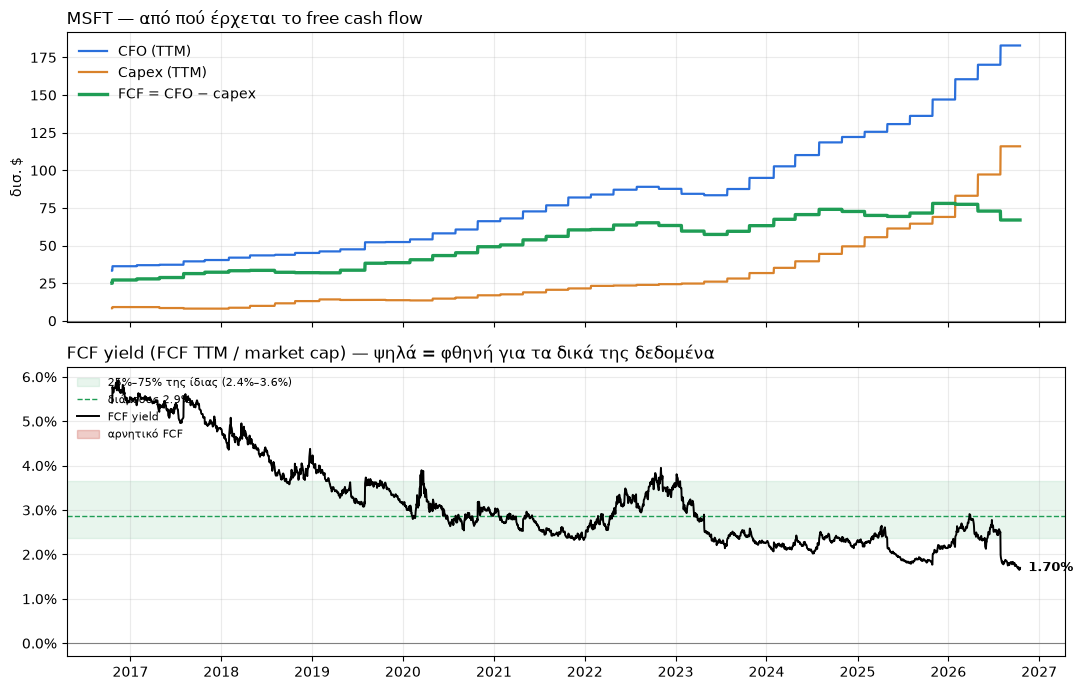

In [8]:
# ── FCF YIELD ─────────────────────────────────────────────────────────────
print_fcf_summary(fcf)
plot_fcf(fcf)
plt.show()

# EV/EBIT — ΑΠΟΤΙΜΗΣΗ ΜΕ ΤΟ ΧΡΕΟΣ ΜΕΣΑ
## ΤΙ ΕΙΝΑΙ:
Το P/E βλέπει μόνο τις μετοχές. Δύο εταιρείες με market cap 100 δισ., η μία με 50 δισ. χρέος και η άλλη με
20 δισ. καθαρό ταμείο, **δεν** είναι εξίσου φθηνές: ολόκληρη η πρώτη κοστίζει 150, η δεύτερη 80.

    EV (enterprise value) = market cap + χρέος − ταμείο
    EBIT                  = λειτουργικό κέρδος, ΠΡΙΝ τους τόκους (πληρώνει δανειστές ΚΑΙ μετόχους)
    EV/EBIT               = σαν P/E, αλλά για όλη την επιχείρηση. Χαμηλό = φθηνή.

## Πώς διαβάζεται το διάγραμμα
    Πάνω: market cap (μπλε) και EV (μαύρο). Ροζ = καθαρό χρέος, πράσινο = καθαρό ταμείο.
          Αν το ροζ μεγαλώνει με τα χρόνια, η εταιρεία δανείζεται.
    Κάτω: EV/EBIT απέναντι στο δικό της ιστορικό. Κάτω από τη ζώνη → φθηνή για τα δικά της δεδομένα.

## Προσοχή
    Για τράπεζες και ασφαλιστικές δεν έχει νόημα (το «χρέος» τους είναι καταθέσεις).
    Το χρέος δεν περιλαμβάνει operating leases· κάποιες εταιρείες δηλώνουν και finance leases, άλλες όχι.
    Για σύγκριση της μετοχής με τον εαυτό της είναι αξιόπιστο· για σύγκριση με άλλες, όχι ακόμα.

── MSFT — EV/EBIT (TTM) ── 2026-10-16 ──
  EV = market cap 3,943.0 + χρέος 40.3 − ταμείο 76.8 = 3,906.5 bn$
     χρέος από: LongTermDebtNoncurrent + LongTermDebtCurrent
  EBIT TTM: 155.24 bn$   → EBIT/EV 3.97%
  EV/EBIT: 25.2   (P/E-λογική, αλλά με το χρέος μέσα)
  Διάμεσος της ίδιας (2016–): 27.5  → σήμερα είναι φθηνότερη απ' ό,τι στο 69% των ημερών
  Καθαρό χρέος / market cap: -1%  (το ταμείο την κάνει φθηνότερη απ' ό,τι δείχνει το P/E)


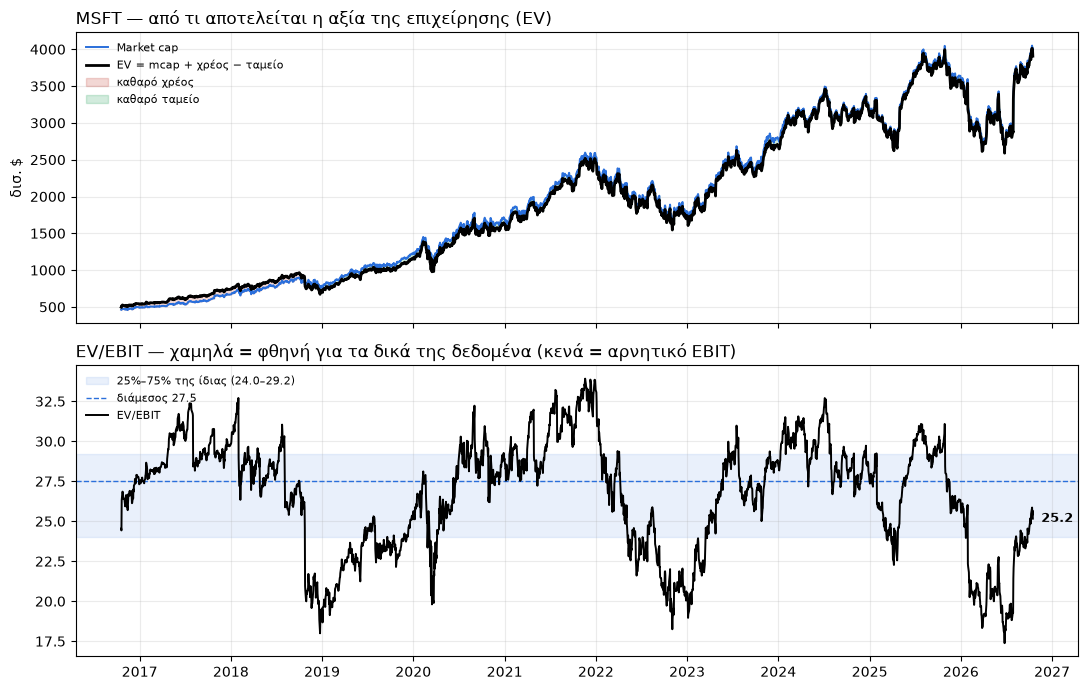

In [9]:
# ── EV/EBIT ───────────────────────────────────────────────────────────────
print_ev_summary(ev)
plot_ev(ev)
plt.show()

# P/S ΚΑΙ SHAREHOLDER YIELD
## P/S
P/S = market cap / έσοδα των τελευταίων 12 μηνών. Δουλεύει και όταν η εταιρεία έχει **ζημιές**,
όπου το P/E και το EV/EBIT δεν έχουν νόημα.
Αγνοεί όμως τα περιθώρια: P/S 5 είναι ακριβό για σούπερ μάρκετ (περιθώριο 3%) και φθηνό για λογισμικό (30%).
Γι' αυτό το συγκρίνουμε μόνο με το δικό της ιστορικό.

## Shareholder yield
(μερίσματα + buybacks των τελευταίων 12 μηνών) / market cap = πόσα μετρητά επέστρεψε στους μετόχους.
Παράδειγμα: μερίσματα 2 + buybacks 3 δισ., market cap 100 δισ. → 5%.

    Μαύρη γραμμή = πόσο έπεσε ΠΡΑΓΜΑΤΙΚΑ ο αριθμός μετοχών σε 12 μήνες.
    Μεγάλα buybacks αλλά γραμμή κοντά στο 0 → τα buybacks απλώς αντισταθμίζουν
    μετοχές που δίνονται στους εργαζόμενους· ο μέτοχος δεν κερδίζει από αυτά.

── MSFT — P/S και επιστροφές στους μετόχους (TTM) ── 2026-10-16 ──
  P/S: 3,943.0 / έσοδα 331.8 bn = 11.88   (διάμεσος της ίδιας 10.56 → φθηνότερη απ' ό,τι στο 31% των ημερών)
  Shareholder yield: 1.24% = μερίσματα 0.67% (26.45 bn) + buybacks 0.56% (22.27 bn)
  Μετοχές σε 12 μήνες: 0.2% λιγότερες


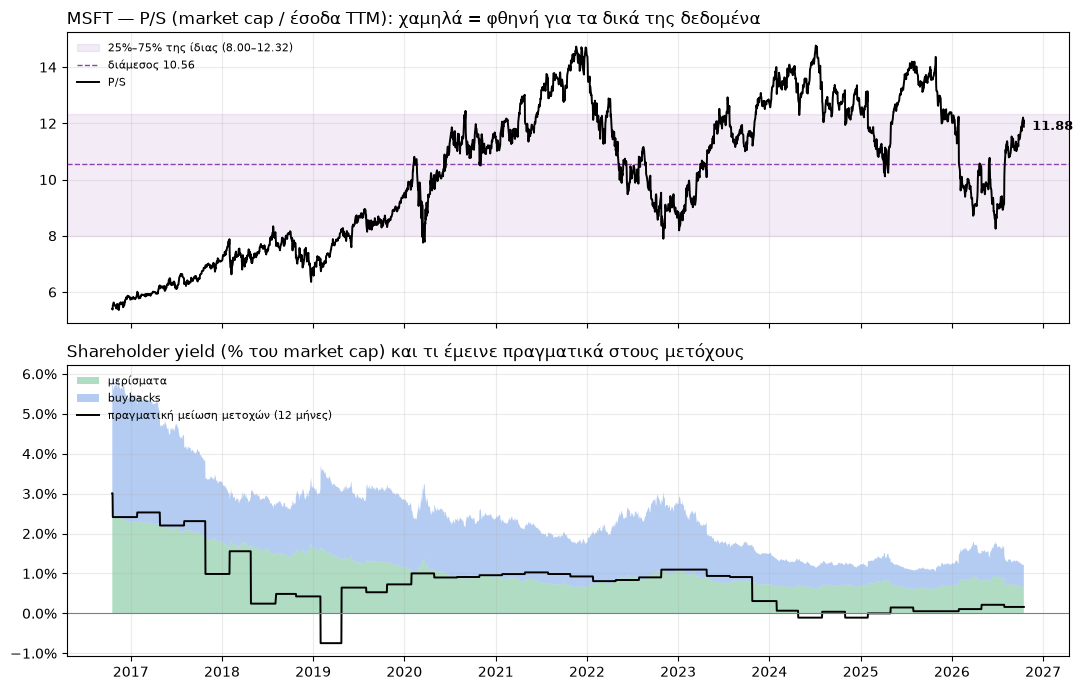

In [10]:
# ── P/S & SHAREHOLDER YIELD ───────────────────────────────────────────────
print_payout_summary(po)
plot_payouts(po)
plt.show()

# ΑΝ ΚΑΤΙ ΦΑΙΝΕΤΑΙ ΠΕΡΙΕΡΓΟ
Βγάλε το `#` από τη γραμμή που χρειάζεσαι.

- **`debug_ttm`:** ο έλεγχος των 30 δευτερολέπτων για το P/E. Όλα τα Q4 με ✓ και ηλικία TTM κάτω από ~150 μέρες = αξιόπιστο.
  ✗ σε κάποιο Q4 = το ιστορικό έχει κενά, το σημερινό P/E στέκει.
- **`debug_fcf`:** από πού βγήκε κάθε τρίμηνο CFO/capex, οι μετοχές, και σύγκριση market cap με το Yahoo.
- **`debug_ev`:** όλα τα tags χρέους/ταμείου, ποιος κανόνας χρησιμοποιήθηκε, και σύγκριση EV με το Yahoo.

Γνωστά κενά (Οκτ. 2026): CRM, KR, APTV, GHC, LHX, TAP (λείπει κατάθεση στη βάση), PARA, XOM (δύο CIK),
νέες εταιρείες από spin-off (χωρίς TTM μέχρι το πρώτο τους πλήρες έτος).

In [11]:
# debug_ttm(TICKER, eng, since="2024-01-01")
# debug_fcf(TICKER, eng)
# debug_ev(TICKER, eng)